# Comparación de algoritmos de aprendizaje supervisado

- **Materia:** Fundamentos de Inteligencia Artificial
- **Docente:** Ing. Carlos André Castro Rodríguez
- **Universidad:** Universidad Tecnológica de Cancún · LITIID71
- **Equipo:**
  - Navarrete Tzuc Jorge
  - Ríos Astudillo Daniel Eduardo
  - Itza Santizo Jarett Osiel
  - Salinas Beatriz Erick

**Objetivo.** Entrenar KNN, SVM y una red neuronal (MLP) con el mismo conjunto de datos y la misma división, y decidir cuál conviene para clasificar tumores como benignos o malignos.

**Decisión que guía todo el análisis.** La clase positiva es **maligno**. Precisión, exhaustividad y F1 se calculan sobre esa clase, porque el error más grave aquí es decirle "benigno" a un tumor maligno.

## 1. Librerías y configuración

In [1]:
import sys
import time
import warnings
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display
from matplotlib.colors import LinearSegmentedColormap
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import (
    GridSearchCV,
    RepeatedStratifiedKFold,
    StratifiedKFold,
    cross_validate,
    train_test_split,
)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

SEMILLA = 42
MODELOS = ["KNN", "SVM", "MLP"]
METRICAS = ["Accuracy", "Precision", "Recall", "F1-score"]

# Cada modelo conserva su color y su marcador en todas las gráficas.
COLOR = {"KNN": "#2a78d6", "SVM": "#eb6834", "MLP": "#1baf7a"}
MARCADOR = {"KNN": "o", "SVM": "s", "MLP": "D"}
FONDO, TINTA, TINTA_SUAVE, REJILLA = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"

plt.rcParams.update(
    {
        "figure.dpi": 110,
        "figure.facecolor": FONDO,
        "axes.facecolor": FONDO,
        "axes.edgecolor": REJILLA,
        "axes.labelcolor": TINTA_SUAVE,
        "axes.titlecolor": TINTA,
        "axes.titlesize": 12,
        "axes.titleweight": "bold",
        "axes.titlelocation": "left",
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": False,
        "grid.color": REJILLA,
        "xtick.color": TINTA_SUAVE,
        "ytick.color": TINTA_SUAVE,
        "legend.frameon": False,
    }
)

print("Python      ", sys.version.split()[0])
print("scikit-learn", sklearn.__version__)
print("pandas      ", pd.__version__)
print("numpy       ", np.__version__)
print("matplotlib  ", matplotlib.__version__)

Python       3.13.18
scikit-learn 1.6.1
pandas       2.2.3
numpy        2.4.6
matplotlib   3.10.0


## 2. Carga del dataset

Usamos *Breast Cancer Wisconsin (Diagnostic)*, el archivo adjunto de la actividad. `wdbc.data` no trae encabezados, así que los nombres salen de la documentación del dataset (`wdbc.names`).

El notebook busca el archivo en `data/`. Si no lo encuentra, como pasa al abrirlo en Colab, lo descarga del repositorio del equipo.

In [2]:
RUTA_LOCAL = Path("data/wdbc.data")
URL_REPO = (
    "https://raw.githubusercontent.com/jorgemx546/"
    "comparacion-aprendizaje-supervisado/main/data/wdbc.data"
)

MEDIDAS = [
    "radius", "texture", "perimeter", "area", "smoothness",
    "compactness", "concavity", "concave_points", "symmetry", "fractal_dimension",
]
RESUMENES = ["mean", "se", "worst"]
CARACTERISTICAS = [f"{m}_{r}" for r in RESUMENES for m in MEDIDAS]

origen = RUTA_LOCAL if RUTA_LOCAL.exists() else URL_REPO
datos = pd.read_csv(origen, header=None, names=["id", "diagnosis", *CARACTERISTICAS])

print("Origen:", origen)
datos.head()

Origen: https://raw.githubusercontent.com/jorgemx546/comparacion-aprendizaje-supervisado/main/data/wdbc.data


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


## 3. Identificación del dataset

In [3]:
conteo = datos["diagnosis"].value_counts()

print(f"Registros:               {datos.shape[0]}")
print(f"Columnas:                {datos.shape[1]}")
print(f"Características entrada: {len(CARACTERISTICAS)}")
print("Variable objetivo:       diagnosis (M = maligno, B = benigno)")
print(f"Valores nulos:           {datos.isna().sum().sum()}")
print(f"ID repetidos:            {datos['id'].duplicated().sum()}")
print(f"Tipos en las entradas:   {datos[CARACTERISTICAS].dtypes.unique().tolist()}")

distribucion = pd.DataFrame(
    {"Registros": conteo, "Porcentaje": (conteo / len(datos) * 100).round(1)}
).rename(index={"B": "Benigno (B)", "M": "Maligno (M)"})
display(distribucion)

Registros:               569
Columnas:                32
Características entrada: 30
Variable objetivo:       diagnosis (M = maligno, B = benigno)
Valores nulos:           0
ID repetidos:            0
Tipos en las entradas:   [dtype('float64')]


,Registros,Porcentaje
diagnosis,,
Benigno (B),357,62.7
Maligno (M),212,37.3


**Qué miden las variables.** Cada registro describe los núcleos celulares de una imagen de punción con aguja fina. Hay 10 medidas y cada una aparece de tres formas: promedio (`_mean`), error estándar (`_se`) y promedio de los tres valores más grandes (`_worst`). Por eso son 30 características.

| Medida | Significado |
|---|---|
| `radius` | Distancia media del centro al perímetro |
| `texture` | Desviación estándar de los valores de gris |
| `perimeter` | Perímetro del núcleo |
| `area` | Área del núcleo |
| `smoothness` | Variación local en la longitud de los radios |
| `compactness` | perímetro² / área − 1 |
| `concavity` | Severidad de las partes cóncavas del contorno |
| `concave_points` | Número de partes cóncavas del contorno |
| `symmetry` | Simetría del núcleo |
| `fractal_dimension` | Aproximación de la "línea de costa" − 1 |

La columna `id` solo identifica al paciente. No aporta información para clasificar y se elimina.

**Lo que esto implica.** Las clases no están balanceadas: hay más benignos que malignos. Eso vuelve engañosa a la exactitud por sí sola, como se comprueba en la sección 9.

In [4]:
rangos = datos[CARACTERISTICAS].describe().T[["min", "mean", "max", "std"]]
display(rangos.loc[["area_worst", "perimeter_mean", "radius_mean", "smoothness_mean", "fractal_dimension_se"]].round(4))

,min,mean,max,std
area_worst,185.2000,880.5831,4254.0000,569.3570
perimeter_mean,43.7900,91.9690,188.5000,24.2990
radius_mean,6.9810,14.1273,28.1100,3.5240
smoothness_mean,0.0526,0.0964,0.1634,0.0141
fractal_dimension_se,0.0009,0.0038,0.0298,0.0026


Las escalas son muy distintas: `area_worst` llega a miles y `fractal_dimension_se` no pasa de centésimas. KNN y SVM usan distancias, así que sin estandarizar `area` dominaría el resultado.

## 4. Separación de entradas y variable objetivo

In [5]:
X = datos[CARACTERISTICAS]
y = datos["diagnosis"].map({"B": 0, "M": 1})  # 1 = maligno, la clase positiva

print("X:", X.shape)
print("y:", y.shape, "| malignos:", int(y.sum()), "| benignos:", int((y == 0).sum()))

X: (569, 30)
y: (569,) | malignos: 212 | benignos: 357


## 5. División en entrenamiento y prueba

Se hace **una sola vez** y los tres modelos usan estos mismos conjuntos. Usamos 80 % / 20 % y `stratify=y` para conservar la proporción de malignos en ambos lados.

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEMILLA
)

division = pd.DataFrame(
    {
        "Registros": [len(y_train), len(y_test)],
        "Malignos": [int(y_train.sum()), int(y_test.sum())],
        "Benignos": [int((y_train == 0).sum()), int((y_test == 0).sum())],
        "% malignos": [round(y_train.mean() * 100, 1), round(y_test.mean() * 100, 1)],
    },
    index=["Entrenamiento", "Prueba"],
)
division

,Registros,Malignos,Benignos,% malignos
Entrenamiento,455,170,285,37.4
Prueba,114,42,72,36.8


## 6. Preprocesamiento: estandarización

`StandardScaler` deja cada característica con media 0 y desviación estándar 1. **Solo aprende del conjunto de entrenamiento**; si viera los datos de prueba, se filtraría información y los resultados saldrían inflados.

In [7]:
escalador = StandardScaler().fit(X_train)
X_train_esc = pd.DataFrame(escalador.transform(X_train), columns=CARACTERISTICAS, index=X_train.index)
X_test_esc = pd.DataFrame(escalador.transform(X_test), columns=CARACTERISTICAS, index=X_test.index)

efecto = pd.DataFrame(
    {
        "Media antes": X_train[["area_worst", "smoothness_mean"]].mean(),
        "Desv. antes": X_train[["area_worst", "smoothness_mean"]].std(ddof=0),
        "Media después": X_train_esc[["area_worst", "smoothness_mean"]].mean(),
        "Desv. después": X_train_esc[["area_worst", "smoothness_mean"]].std(ddof=0),
    }
)
efecto.round(4) + 0.0  # sumar 0.0 evita que se muestre -0.0

,Media antes,Desv. antes,Media después,Desv. después
area_worst,890.5692,581.7059,0.0,1.0
smoothness_mean,0.0960,0.0143,0.0,1.0


Esta celda muestra el efecto. Para entrenar metemos el escalador en un `Pipeline`, de modo que dentro de la validación cruzada se ajusta de nuevo en cada partición y tampoco ve los datos con los que se valida.

## 7. Entrenamiento de los tres modelos

Elegimos los hiperparámetros con `GridSearchCV`, usando **validación cruzada de 5 particiones solo sobre entrenamiento**. El conjunto de prueba no participa en ninguna elección. Todos se seleccionan con el mismo criterio, F1 sobre la clase maligna, para que la comparación sea justa.

In [8]:
particiones = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)

busquedas = {
    "KNN": (
        KNeighborsClassifier(),
        {
            "modelo__n_neighbors": list(range(1, 32, 2)),
            "modelo__weights": ["uniform", "distance"],
        },
    ),
    "SVM": (
        SVC(),
        [
            {"modelo__kernel": ["linear"], "modelo__C": [0.01, 0.1, 1, 10, 100]},
            {
                "modelo__kernel": ["rbf"],
                "modelo__C": [0.1, 1, 10, 100],
                "modelo__gamma": ["scale", 0.001, 0.01, 0.1],
            },
        ],
    ),
    "MLP": (
        MLPClassifier(max_iter=3000, random_state=SEMILLA),
        {
            "modelo__hidden_layer_sizes": [(16,), (32,), (32, 16)],
            "modelo__alpha": [0.0001, 0.01, 0.1, 1.0, 3.0, 10.0],
        },
    ),
}

ajustes, modelos, tiempos = {}, {}, {}
for nombre, (estimador, rejilla) in busquedas.items():
    tubo = Pipeline([("escalador", StandardScaler()), ("modelo", estimador)])
    busqueda = GridSearchCV(tubo, rejilla, scoring="f1", cv=particiones, n_jobs=-1)
    busqueda.fit(X_train, y_train)
    ajustes[nombre] = busqueda
    modelos[nombre] = busqueda.best_estimator_
    tiempos[nombre] = {"Entrenar modelo final (ms)": busqueda.refit_time_ * 1000}

elegidos = pd.DataFrame(
    {
        "Hiperparámetros elegidos": {
            n: ", ".join(f"{k.replace('modelo__', '')}={v}" for k, v in a.best_params_.items())
            for n, a in ajustes.items()
        },
        "F1 en validación cruzada": {n: round(a.best_score_, 4) for n, a in ajustes.items()},
    }
)
pd.set_option("display.max_colwidth", None)
elegidos

,Hiperparámetros elegidos,F1 en validación cruzada
KNN,"n_neighbors=3, weights=uniform",0.9633
SVM,"C=10, gamma=scale, kernel=rbf",0.9674
MLP,"alpha=3.0, hidden_layer_sizes=(16,)",0.9727


## 8. Prueba con los mismos datos

Los tres modelos predicen exactamente el mismo conjunto de prueba, que no habían visto.

In [9]:
def evaluar(y_real, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_real, y_pred, labels=[0, 1]).ravel()
    return {
        "Accuracy": accuracy_score(y_real, y_pred),
        "Precision": precision_score(y_real, y_pred, zero_division=0),
        "Recall": recall_score(y_real, y_pred, zero_division=0),
        "F1-score": f1_score(y_real, y_pred, zero_division=0),
        "Errores": int(fp + fn),
        "FN (maligno como benigno)": int(fn),
        "FP (benigno como maligno)": int(fp),
    }


predicciones = {}
for nombre, modelo in modelos.items():
    predicciones[nombre] = modelo.predict(X_test)
    # Mediana de 20 repeticiones: la primera llamada suele tardar más de lo normal.
    medidas = []
    for _ in range(20):
        inicio = time.perf_counter()
        modelo.predict(X_test)
        medidas.append((time.perf_counter() - inicio) * 1000)
    tiempos[nombre]["Predecir prueba (ms)"] = float(np.median(medidas))

for nombre in MODELOS:
    print(f"--- {nombre} ---")
    print(classification_report(y_test, predicciones[nombre], target_names=["Benigno", "Maligno"], digits=4))

--- KNN ---
              precision    recall  f1-score   support

     Benigno     0.9221    0.9861    0.9530        72
     Maligno     0.9730    0.8571    0.9114        42

    accuracy                         0.9386       114
   macro avg     0.9475    0.9216    0.9322       114
weighted avg     0.9408    0.9386    0.9377       114

--- SVM ---
              precision    recall  f1-score   support

     Benigno     0.9600    1.0000    0.9796        72
     Maligno     1.0000    0.9286    0.9630        42

    accuracy                         0.9737       114
   macro avg     0.9800    0.9643    0.9713       114
weighted avg     0.9747    0.9737    0.9735       114

--- MLP ---
              precision    recall  f1-score   support

     Benigno     0.9730    1.0000    0.9863        72
     Maligno     1.0000    0.9524    0.9756        42

    accuracy                         0.9825       114
   macro avg     0.9865    0.9762    0.9810       114
weighted avg     0.9829    0.9825    0

### Matrices de confusión

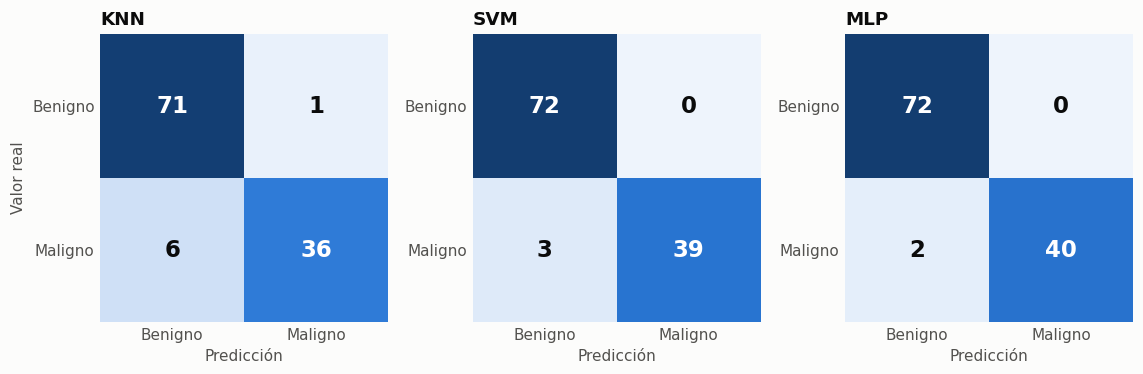

In [10]:
mapa = LinearSegmentedColormap.from_list("azul", ["#eef4fc", "#2a78d6", "#123a6b"])
fig, ejes = plt.subplots(1, 3, figsize=(10.5, 3.5))
clases = ["Benigno", "Maligno"]
maximo = len(y_test)

for eje, nombre in zip(ejes, MODELOS):
    matriz = confusion_matrix(y_test, predicciones[nombre], labels=[0, 1])
    eje.imshow(matriz, cmap=mapa, vmin=0, vmax=maximo * 0.65)
    eje.set_title(nombre)
    eje.set_xticks([0, 1], clases)
    eje.set_yticks([0, 1], clases)
    eje.set_xlabel("Predicción")
    eje.tick_params(length=0)
    for spine in eje.spines.values():
        spine.set_visible(False)
    for fila in range(2):
        for col in range(2):
            valor = matriz[fila, col]
            eje.text(
                col, fila, valor, ha="center", va="center", fontsize=15, fontweight="bold",
                color="white" if valor > maximo * 0.25 else TINTA,
            )
ejes[0].set_ylabel("Valor real")
fig.tight_layout()
plt.show()

## 9. Tabla comparativa y gráficas

La fila `Siempre benigno` es una referencia: un clasificador sin ninguna inteligencia que responde siempre la clase más común. Sirve para ver cuánto vale realmente una exactitud alta en este problema.

In [11]:
comparacion = pd.DataFrame({n: evaluar(y_test, predicciones[n]) for n in MODELOS}).T

referencia = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
comparacion_con_referencia = pd.concat(
    [comparacion, pd.DataFrame({"Siempre benigno": evaluar(y_test, referencia.predict(X_test))}).T]
)
CONTEOS = ["Errores", "FN (maligno como benigno)", "FP (benigno como maligno)"]
for tabla in (comparacion, comparacion_con_referencia):
    tabla[METRICAS] = tabla[METRICAS].astype(float)
    tabla[CONTEOS] = tabla[CONTEOS].astype(int)
comparacion_con_referencia.round(4)

,Accuracy,Precision,Recall,F1-score,Errores,FN (maligno como benigno),FP (benigno como maligno)
KNN,0.9386,0.973,0.8571,0.9114,7,6,1
SVM,0.9737,1.000,0.9286,0.9630,3,3,0
MLP,0.9825,1.000,0.9524,0.9756,2,2,0
Siempre benigno,0.6316,0.000,0.0000,0.0000,42,42,0


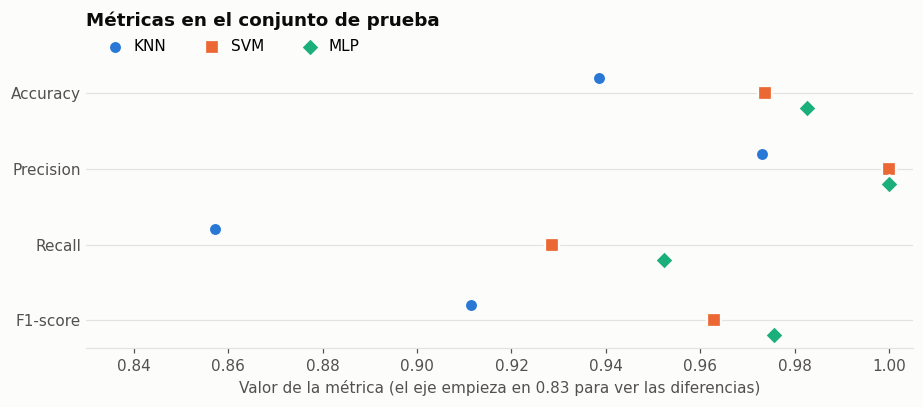

In [12]:
fig, eje = plt.subplots(figsize=(8.5, 3.8))
filas = np.arange(len(METRICAS))[::-1]
desfase = {"KNN": 0.2, "SVM": 0.0, "MLP": -0.2}

for fila in filas:
    eje.axhline(fila, color=REJILLA, linewidth=0.8, zorder=1)
for nombre in MODELOS:
    eje.scatter(
        comparacion.loc[nombre, METRICAS].to_numpy(dtype=float),
        filas + desfase[nombre],
        s=75, marker=MARCADOR[nombre], color=COLOR[nombre],
        edgecolors=FONDO, linewidths=1.5, zorder=3, label=nombre,
    )

limite = np.floor(comparacion[METRICAS].to_numpy(dtype=float).min() * 50) / 50 - 0.01
eje.set_xlim(limite, 1.005)
eje.set_yticks(filas, METRICAS)
eje.tick_params(axis="y", length=0)
eje.spines["left"].set_visible(False)
eje.set_xlabel(f"Valor de la métrica (el eje empieza en {limite:.2f} para ver las diferencias)")
eje.set_title("Métricas en el conjunto de prueba", pad=26)
eje.legend(ncols=3, loc="lower left", bbox_to_anchor=(0, 0.99), handletextpad=0.2)
fig.tight_layout()
plt.show()

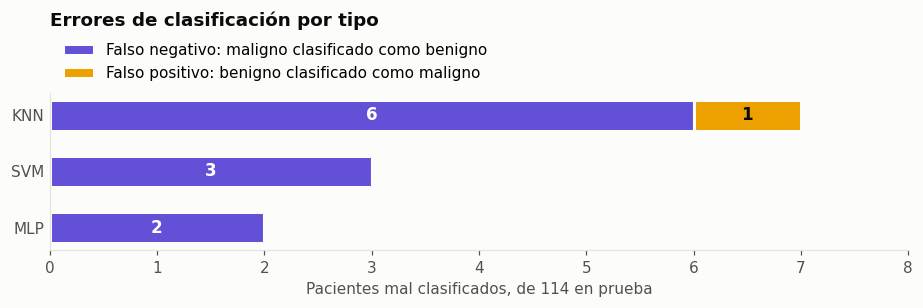

In [13]:
fig, eje = plt.subplots(figsize=(8.5, 2.9))
COLOR_FN, COLOR_FP = "#6250d6", "#eda100"
posiciones = np.arange(len(MODELOS))[::-1]

fn = comparacion["FN (maligno como benigno)"].astype(int).to_numpy()
fp = comparacion["FP (benigno como maligno)"].astype(int).to_numpy()
eje.barh(posiciones, fn, height=0.55, color=COLOR_FN, edgecolor=FONDO, linewidth=2, label="Falso negativo: maligno clasificado como benigno")
eje.barh(posiciones, fp, left=fn, height=0.55, color=COLOR_FP, edgecolor=FONDO, linewidth=2, label="Falso positivo: benigno clasificado como maligno")

for y_pos, n_fn, n_fp in zip(posiciones, fn, fp):
    if n_fn:
        eje.text(n_fn / 2, y_pos, str(n_fn), ha="center", va="center", color="white", fontsize=11, fontweight="bold")
    if n_fp:
        eje.text(n_fn + n_fp / 2, y_pos, str(n_fp), ha="center", va="center", color=TINTA, fontsize=11, fontweight="bold")

eje.set_yticks(posiciones, MODELOS)
eje.tick_params(axis="y", length=0)
eje.set_xticks(range(0, int((fn + fp).max()) + 2))
eje.set_xlabel(f"Pacientes mal clasificados, de {len(y_test)} en prueba")
eje.set_title("Errores de clasificación por tipo", pad=44)
eje.legend(loc="lower left", bbox_to_anchor=(0, 0.99))
fig.tight_layout()
plt.show()

## 10. Comportamiento de cada algoritmo

Un conjunto de prueba de 114 pacientes da pocos errores, así que un solo caso mueve las métricas. Estas pruebas revisan si las diferencias de la tabla son estables. **Ninguna se usó para elegir hiperparámetros.**

### 10.1 Estabilidad con validación cruzada repetida

5 particiones repetidas 10 veces, solo con datos de entrenamiento: 50 evaluaciones por modelo.

In [14]:
repetida = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=SEMILLA)
puntuaciones = {"Accuracy": "accuracy", "Recall": "recall", "F1-score": "f1"}

estabilidad = {}
for nombre, modelo in modelos.items():
    resultado = cross_validate(clone(modelo), X_train, y_train, cv=repetida, scoring=puntuaciones, n_jobs=-1)
    estabilidad[nombre] = {m: resultado[f"test_{m}"] for m in puntuaciones}

tabla_estabilidad = pd.DataFrame(
    {
        n: {
            f"{m} {etiqueta}": funcion(v[m])
            for m in puntuaciones
            for etiqueta, funcion in [("media", np.mean), ("desv.", np.std)]
        }
        for n, v in estabilidad.items()
    }
).T.round(4)
tabla_estabilidad

,Accuracy media,Accuracy desv.,Recall media,Recall desv.,F1-score media,F1-score desv.
KNN,0.9684,0.0206,0.9276,0.0479,0.9558,0.0295
SVM,0.9741,0.0163,0.9612,0.0297,0.9651,0.0218
MLP,0.9754,0.0162,0.9506,0.0355,0.9663,0.0224


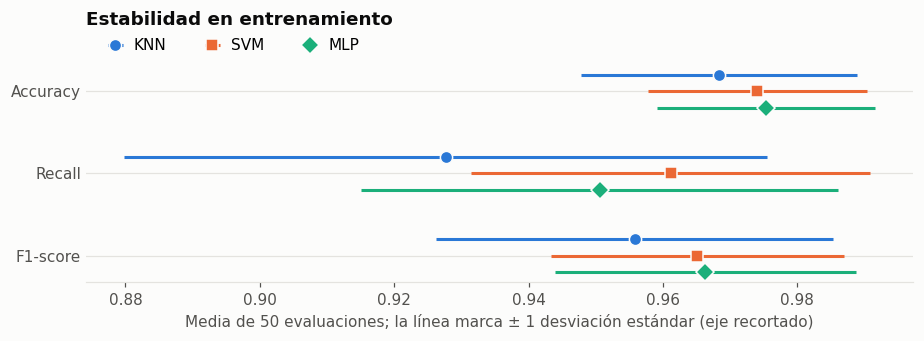

In [15]:
fig, eje = plt.subplots(figsize=(8.5, 3.2))
nombres_metrica = list(puntuaciones)
filas = np.arange(len(nombres_metrica))[::-1]

for fila in filas:
    eje.axhline(fila, color=REJILLA, linewidth=0.8, zorder=1)
for nombre in MODELOS:
    medias = [estabilidad[nombre][m].mean() for m in nombres_metrica]
    desv = [estabilidad[nombre][m].std() for m in nombres_metrica]
    eje.errorbar(
        medias, filas + desfase[nombre], xerr=desv, fmt=MARCADOR[nombre], color=COLOR[nombre],
        markersize=8, markeredgecolor=FONDO, elinewidth=2, capsize=0, zorder=3, label=nombre,
    )

eje.set_yticks(filas, nombres_metrica)
eje.tick_params(axis="y", length=0)
eje.spines["left"].set_visible(False)
eje.set_xlabel("Media de 50 evaluaciones; la línea marca ± 1 desviación estándar (eje recortado)")
eje.set_title("Estabilidad en entrenamiento", pad=26)
eje.legend(ncols=3, loc="lower left", bbox_to_anchor=(0, 0.99), handletextpad=0.2)
fig.tight_layout()
plt.show()

### 10.2 Entrenamiento contra prueba (sobreajuste)

In [16]:
sobreajuste = pd.DataFrame(
    {
        n: {
            "Accuracy entrenamiento": accuracy_score(y_train, m.predict(X_train)),
            "Accuracy prueba": accuracy_score(y_test, predicciones[n]),
        }
        for n, m in modelos.items()
    }
).T
sobreajuste["Diferencia"] = sobreajuste["Accuracy entrenamiento"] - sobreajuste["Accuracy prueba"]
sobreajuste.round(4) + 0.0  # sumar 0.0 evita que se muestre -0.0

,Accuracy entrenamiento,Accuracy prueba,Diferencia
KNN,0.9846,0.9386,0.0460
SVM,0.9890,0.9737,0.0153
MLP,0.9824,0.9825,0.0000


### 10.3 Qué pasa sin estandarizar

Se usan los mismos hiperparámetros, pero sin escalador. El experimento solo ilustra la sensibilidad a la escala. La celda también cuenta cuántas veces la red avisa que no convergió.

In [17]:
sin_escala = {}
with warnings.catch_warnings(record=True) as avisos:
    warnings.simplefilter("always", ConvergenceWarning)
    for nombre, modelo in modelos.items():
        crudo = clone(modelo.named_steps["modelo"]).fit(X_train, y_train)
        resultado = evaluar(y_test, crudo.predict(X_test))
        sin_escala[nombre] = {
            "Accuracy con escala": comparacion.loc[nombre, "Accuracy"],
            "Accuracy sin escala": resultado["Accuracy"],
            "Recall con escala": comparacion.loc[nombre, "Recall"],
            "Recall sin escala": resultado["Recall"],
            "FN sin escala": resultado["FN (maligno como benigno)"],
        }

print("Avisos de no convergencia:", sum(issubclass(a.category, ConvergenceWarning) for a in avisos))
pd.DataFrame(sin_escala).T.astype(float).round(4)

Avisos de no convergencia: 0


,Accuracy con escala,Accuracy sin escala,Recall con escala,Recall sin escala,FN sin escala
KNN,0.9386,0.9211,0.8571,0.7857,9.0
SVM,0.9737,0.8947,0.9286,0.7143,12.0
MLP,0.9825,0.9035,0.9524,0.7619,10.0


### 10.4 Efecto de la inicialización

KNN y SVM dan siempre el mismo resultado con los mismos datos. La red neuronal arranca con pesos aleatorios, así que se entrena con 20 semillas distintas.

In [18]:
corridas = []
for semilla in range(20):
    red = clone(modelos["MLP"]).set_params(modelo__random_state=semilla).fit(X_train, y_train)
    corridas.append(evaluar(y_test, red.predict(X_test)))
corridas = pd.DataFrame(corridas)

columnas = ["Accuracy", "Recall", "Errores", "FN (maligno como benigno)"]
corridas[columnas].astype(float).agg(["min", "mean", "max", "std"]).round(4)

,Accuracy,Recall,Errores,FN (maligno como benigno)
min,0.9825,0.9524,2.0,2.0
mean,0.9825,0.9524,2.0,2.0
max,0.9825,0.9524,2.0,2.0
std,0.0000,0.0000,0.0,0.0


### 10.5 Cómo aprende cada uno

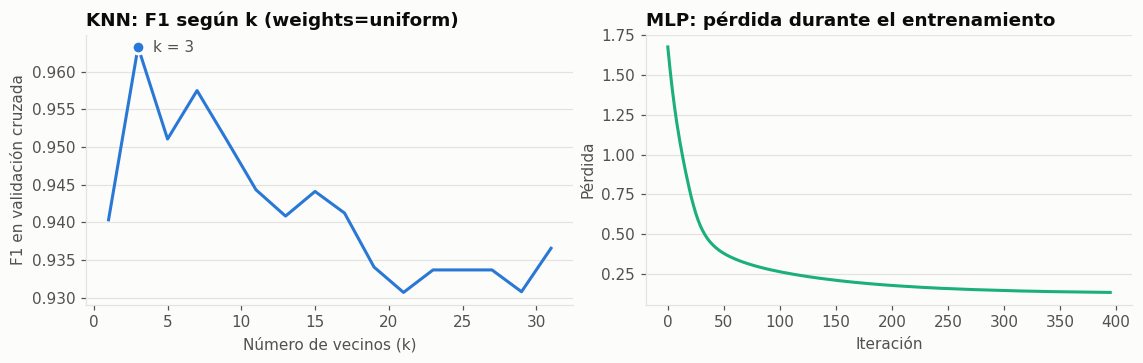

SVM: kernel=rbf, 82 vectores de soporte de 455 registros (18.0%)
MLP: 396 iteraciones, capas ocultas (16,), 513 parámetros
KNN: guarda los 455 registros de entrenamiento y calcula distancias al predecir


In [19]:
fig, (izquierda, derecha) = plt.subplots(1, 2, figsize=(10.5, 3.4))

resultados_knn = pd.DataFrame(ajustes["KNN"].cv_results_)
peso = ajustes["KNN"].best_params_["modelo__weights"]
curva = resultados_knn[resultados_knn["param_modelo__weights"] == peso]
vecinos = curva["param_modelo__n_neighbors"].astype(int)
izquierda.plot(vecinos, curva["mean_test_score"], color=COLOR["KNN"], linewidth=2)
elegido = ajustes["KNN"].best_params_["modelo__n_neighbors"]
izquierda.scatter(
    [elegido], [ajustes["KNN"].best_score_], s=70, color=COLOR["KNN"],
    edgecolors=FONDO, linewidths=2, zorder=3,
)
izquierda.annotate(f"k = {elegido}", (elegido, ajustes["KNN"].best_score_), xytext=(10, -3), textcoords="offset points", color=TINTA_SUAVE)
izquierda.set_title(f"KNN: F1 según k (weights={peso})")
izquierda.set_xlabel("Número de vecinos (k)")
izquierda.set_ylabel("F1 en validación cruzada")
izquierda.grid(axis="y")

derecha.plot(modelos["MLP"].named_steps["modelo"].loss_curve_, color=COLOR["MLP"], linewidth=2)
derecha.set_title("MLP: pérdida durante el entrenamiento")
derecha.set_xlabel("Iteración")
derecha.set_ylabel("Pérdida")
derecha.grid(axis="y")

fig.tight_layout()
plt.show()

svm = modelos["SVM"].named_steps["modelo"]
red = modelos["MLP"].named_steps["modelo"]
print(f"SVM: kernel={svm.kernel}, {svm.n_support_.sum()} vectores de soporte de {len(X_train)} registros ({svm.n_support_.sum() / len(X_train):.1%})")
print(f"MLP: {red.n_iter_} iteraciones, capas ocultas {red.hidden_layer_sizes}, {sum(c.size for c in red.coefs_) + sum(i.size for i in red.intercepts_)} parámetros")
print(f"KNN: guarda los {len(X_train)} registros de entrenamiento y calcula distancias al predecir")

### 10.6 Tiempos

Son milisegundos en una sola máquina y cambian entre corridas. Solo sirven para ver el orden de magnitud.

In [20]:
pd.DataFrame(tiempos).T.round(2)

,Entrenar modelo final (ms),Predecir prueba (ms)
KNN,6.80,4.81
SVM,13.39,3.77
MLP,579.84,2.12


### 10.7 ¿Fallan en los mismos pacientes?

In [21]:
casos = pd.DataFrame({n: predicciones[n] for n in MODELOS}, index=y_test.index)
fallos = casos.ne(y_test, axis=0)
con_error = fallos.any(axis=1)

texto = {0: "Benigno", 1: "Maligno"}
detalle = casos[con_error].replace(texto)
detalle.insert(0, "Real", y_test[con_error].map(texto))
detalle["Modelos que fallan"] = fallos[con_error].sum(axis=1)
detalle = detalle.join(X_test.loc[con_error, ["radius_worst", "concave_points_worst", "texture_mean"]].round(3))

print("Pacientes con al menos un error:", int(con_error.sum()), "de", len(y_test))
print("Pacientes en los que fallan los tres:", int((fallos.sum(axis=1) == 3).sum()))
detalle.sort_values("Modelos que fallan", ascending=False)

Pacientes con al menos un error: 7 de 114
Pacientes en los que fallan los tres: 2


,Real,KNN,SVM,MLP,Modelos que fallan,radius_worst,concave_points_worst,texture_mean
73,Maligno,Benigno,Benigno,Benigno,3,16.57,0.138,15.79
205,Maligno,Benigno,Benigno,Benigno,3,17.77,0.125,16.68
99,Maligno,Benigno,Benigno,Maligno,2,16.33,0.156,19.77
208,Benigno,Maligno,Benigno,Benigno,1,14.55,0.113,22.54
385,Maligno,Benigno,Maligno,Maligno,1,15.79,0.136,23.29
277,Maligno,Benigno,Maligno,Maligno,1,19.96,0.129,19.98
329,Maligno,Benigno,Maligno,Maligno,1,17.73,0.105,21.88


## 11. Resumen calculado

In [22]:
print("Mayor accuracy :", comparacion["Accuracy"].astype(float).idxmax(), f"({comparacion['Accuracy'].astype(float).max():.4f})")
print("Mayor recall   :", comparacion["Recall"].astype(float).idxmax(), f"({comparacion['Recall'].astype(float).max():.4f})")
print("Mayor F1-score :", comparacion["F1-score"].astype(float).idxmax(), f"({comparacion['F1-score'].astype(float).max():.4f})")
print("Más errores    :", comparacion["Errores"].astype(int).idxmax(), f"({comparacion['Errores'].astype(int).max()})")
print("Más FN         :", comparacion["FN (maligno como benigno)"].astype(int).idxmax(), f"({comparacion['FN (maligno como benigno)'].astype(int).max()})")

Mayor accuracy : MLP (0.9825)
Mayor recall   : MLP (0.9524)
Mayor F1-score : MLP (0.9756)
Más errores    : KNN (7)
Más FN         : KNN (6)


## 12. Respuestas y conclusiones

| Modelo | Accuracy | Precision | Recall | F1-score | FN | FP |
|---|---|---|---|---|---|---|
| KNN (k=3) | 0.9386 | 0.9730 | 0.8571 | 0.9114 | 6 | 1 |
| SVM (RBF, C=10) | 0.9737 | 1.0000 | 0.9286 | 0.9630 | 3 | 0 |
| MLP (16 neuronas, alpha=3) | 0.9825 | 1.0000 | 0.9524 | 0.9756 | 2 | 0 |

### ¿Cuál de los tres algoritmos obtuvo el mejor rendimiento?

La **red neuronal (MLP)**. En el conjunto de prueba tuvo los valores más altos de exactitud (0.9825), exhaustividad (0.9524) y F1 (0.9756), y empató con SVM en precisión (1.0000).

Su ventaja sobre SVM es de **un solo paciente** (2 errores contra 3), así que no alcanza para decir que es claramente superior. En la validación cruzada repetida quedan muy parejos: MLP tiene más exactitud (0.9754 contra 0.9741), pero SVM tiene más recall (0.9612 contra 0.9506), y las diferencias son menores que su desviación estándar. KNN sí queda por debajo en ambas pruebas.

### ¿Cuál presentó más errores de clasificación?

**KNN**, con 7 errores de 114: 6 falsos negativos y 1 falso positivo. Es más del doble que SVM (3) y más del triple que MLP (2). Además, es el único que clasificó un tumor benigno como maligno.

### ¿Qué diferencias observaste en su comportamiento?

- **Tipo de error.** Casi todos los errores son del mismo tipo: 11 de 12 son falsos negativos. Los tres modelos tienden a dejar pasar malignos y casi nunca alarman de más. SVM y MLP tienen precisión perfecta, pero aun así no detectan todos los malignos.
- **Errores compartidos.** Los errores están anidados: los 2 pacientes en que falla MLP también los falla SVM, y los 3 de SVM también los falla KNN. Los pacientes 73 y 205, ambos malignos, engañan a los tres modelos.
- **Sobreajuste.** KNN tiene la mayor diferencia entre entrenamiento y prueba (0.9846 contra 0.9386, una brecha de 0.0460). SVM tiene 0.0153 y MLP prácticamente ninguna.
- **Estabilidad.** KNN es el que más varía en recall entre particiones (desviación de 0.0479, contra 0.0297 de SVM y 0.0355 de MLP). La red neuronal, que podría variar por sus pesos iniciales, dio el mismo resultado con las 20 semillas probadas. Una posible razón es su regularización fuerte (alpha=3.0).
- **Sensibilidad a la escala.** Sin estandarizar, los tres empeoran. SVM cae más (accuracy de 0.9737 a 0.8947, recall de 0.9286 a 0.7143), seguido de MLP (recall de 0.9524 a 0.7619) y KNN (recall de 0.8571 a 0.7857). Hay que considerar que los hiperparámetros se eligieron con datos estandarizados.
- **Forma de aprender.** KNN no construye un modelo: guarda los 455 registros y calcula distancias al predecir. Su F1 baja de 0.963 con k=3 hasta cerca de 0.93 con k altos. SVM resume la frontera con 82 vectores de soporte (18 % de los registros). MLP ajusta 513 parámetros en 396 iteraciones.
- **Costo.** MLP es el más lento de entrenar, decenas de veces más que los otros dos, aunque sigue siendo menos de un segundo. Al predecir los tres tardan pocos milisegundos, así que el tiempo no decide nada en este problema.

### ¿Elegirías el algoritmo con mayor exactitud para este problema?

**Elegiríamos MLP, pero no por su exactitud.** Lo elegimos porque también tiene el mayor recall y, por lo tanto, los menos falsos negativos. Aquí el algoritmo con mayor exactitud coincide con el de mayor recall, pero eso podría no pasar.

Los dos errores no cuestan lo mismo. Un falso positivo lleva a una persona sana a más estudios, lo cual causa angustia y gastos, pero se corrige. Un falso negativo manda a casa a una paciente con un tumor maligno y retrasa su tratamiento. Por eso la métrica principal debe ser el recall de la clase maligna, y no la exactitud.

La referencia `Siempre benigno` muestra el problema: obtiene una exactitud de 0.6316 sin detectar **ni un solo** tumor maligno, porque los benignos son mayoría. Además, cada falso negativo pesa poco en la exactitud (0.88 puntos porcentuales) y mucho en el recall (2.38 puntos).

Si se quisiera un modelo que no dependa de pesos aleatorios, SVM también sería una opción defendible, porque sus resultados son muy cercanos y en validación cruzada tuvo un recall un poco mayor.

### Limitaciones

- La prueba tiene 114 pacientes y 42 malignos, y se usó una sola división. Por eso, 1 o 2 errores de diferencia no demuestran una superioridad real.
- Ningún modelo detectó todos los malignos: MLP dejó pasar 2 de 42. Para acercarse al uso real habría que ajustar el umbral de decisión para reducir falsos negativos, a cambio de más falsos positivos. No lo evaluamos en esta actividad.
- Este trabajo es un ejercicio académico y no sirve como herramienta de diagnóstico.